# Model Complexity and Model Selection

Bias-variance trade-off, cross-validation, and regularisation for model selection.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Machine%20learning/Elements%20of%20Machine%20Learning,%20Linear%20Models%20for%20Classification%20and%20regression%2099/Model%20Complexity%20and%20Model%20Selection.ipynb)

# **1 Model Complexity and Model Selection**

***[KNN Regressor]***

***I Implement a KNN regressor using the scikit-learn conventions.***

In [ ]:
from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from scipy.spatial import KDTree
import numpy as np
diabetes = load_diabetes()
diabetes.data.shape, diabetes.target.shape, diabetes.feature_names
from matplotlib import pyplot as plt


In [ ]:
class KnnRegressor(BaseEstimator):
  def __init__(self, k=5):
    self.k = k

  def fit(self, x, y):
    self.x_train_ = np.array(x)
    self.y_train_ = np.array(y)
    self.tree_ = KDTree(self.x_train_)
    return self

  def predict(self, x):
    x = np.array(x)
    _, neighbours = self.tree_.query(x, k=self.k)
    if self.k == 1:
      predictions = self.y_train_[neighbours]
    else:
      predictions = np.mean(self.y_train_[neighbours], axis=1)
    return predictions

***II To test implementation, load the dataset diabetes through the functions load diabetes, which is available in the module sklearn.datasets. For this dataset, perform a training/test split (using a fraction of 0.7 of the data as training data), fit KNN regressor to the train- ing portion (using some guess for a good value of k), and report the training and test errors.***

In [ ]:
def train_test_split(x, y, train_size=0.7, random_state=None):
    RNG = np.random.default_rng(random_state)
    N = len(x)
    N_train = round(N*train_size)
    idx_train = RNG.choice(N, N_train, replace=False)
    idx_test = np.setdiff1d(np.arange(N), idx_train)
    RNG.shuffle(idx_test)
    return x[idx_train], x[idx_test], y[idx_train], y[idx_test]

x_train, x_test, y_train, y_test = train_test_split(diabetes.data, diabetes.target, train_size=0.7, random_state=1)

In [ ]:
knn = KnnRegressor(k=5)
knn.fit(x_train, y_train)
y_hat_test = knn.predict(x_test)

y_hat_test


array([158. , 196.8, 157.8, 138. , 130.2, 189.4,  76.8, 178.6,  83.6,
       175.4, 109. , 242.8, 218. , 154.4, 167. , 140.8, 143.2,  75.4,
       186.6, 265.4,  96. , 131.4, 116. ,  87. , 158.4, 275.4, 208.2,
       151.6, 125.2, 214.4, 119.8, 121.6, 142.2, 172.2, 200.2, 164.8,
       104.2, 191.2, 131.2, 110. , 127.2, 230.8, 106.4, 171. , 165. ,
       204.6, 195. , 259.8, 191.4, 102.2,  86.4, 286.8, 156.6, 163.8,
       229.8,  90.6,  94.8,  97.6, 213.4,  98. , 190. , 165. ,  80.6,
        78.4,  86.8, 239.8,  93.2,  91.8, 275.6,  88. , 236. , 247.8,
       123.8, 100.2, 103.6, 150.2, 161.2, 113.6, 136.8,  56.6, 175.8,
        96.6, 204.4, 283. ,  92.6, 226.4, 123.6,  97. ,  90.6, 188.8,
        80. , 194.6, 151. , 111.6, 142.4, 107. , 164. , 193.8,  54.4,
        97.2, 143. ,  74. , 117. , 212.6, 197.4, 117.8, 117.4, 206.6,
       100. , 149.4, 120.4,  93.6, 109. , 126.8, 157.2, 174.4, 226.4,
        59.2, 200.4, 266.2,  88.6, 121.2, 105.2, 112.4, 115.8, 200.4,
        91.2, 119.4,

In [ ]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

y_hat_train = knn.predict(x_train)
print("training error-",mse(y_train, y_hat_train),"testing error-",mse(y_test, y_hat_test))

training error- 2462.266148867314 testing error- 3708.017142857143


***[L-fold Cross Validation]***

***I Implement a L-Fold Cross Validation (CV) scheme using the scikit-learn convention for data splitters, i.e., using the following skeleton. Note that this is usually referred to as K-fold cross-validation. We are simply using the symbol L here to differentiate the cross validation parameter from the number of neighbours in K-nearest neighbours.***

In [ ]:
class LFold:
  def __init__(self, n_splits=5, shuffle=False, random_state=None): # ADD PARAMETERS AS REQUIRED
      # YOUR CODE HERE
      self.n_splits = n_splits
      self.shuffle = shuffle
      self.random_state = random_state

  def get_n_splits(self, x=None, y=None, groups=None):
      # YOUR CODE HERE
      return self.n_splits
  def split(self, x, y=None, groups=None):
      # YOUR CODE HERE
      n_samples = len(x)
      indices = np.arange(n_samples)
      if self.shuffle:
          rng = np.random.default_rng(self.random_state)
          rng.shuffle(indices)
      fold_sizes = np.full(self.n_splits, n_samples // self.n_splits, dtype=int)
      fold_sizes[:n_samples % self.n_splits] += 1

      current = 0
      for fold_size in fold_sizes:
          start, stop = current, current + fold_size
          test_idx = indices[start:stop]
          train_idx = np.concatenate((indices[:start], indices[stop:]))
          yield train_idx, test_idx
          current = stop

***Note: As usual, there are many ways to implement the desired solution. For one of the ways, the function np.concatenate can be useful to build up the array if the train indices.
Test our implementation for correctness by running a simple example like the following.
         for idx_train, idx_test in LFold(5).split(list(range(20))):
             print(idx_train, idx_test)***

In [ ]:
# Test with dummy data
lfold = LFold(n_splits=5, shuffle=True, random_state=42)
x = np.arange(20)

for i, (train_idx, test_idx) in enumerate(lfold.split(x)):
    print(f"Fold {i + 1}")
    print("Train:", train_idx)
    print("Test: ", test_idx)
    print()


Fold 1
Train: [12 10  6 19  3  0 16  5 11 18  2  4 17  1 13  8]
Test:  [15  9 14  7]

Fold 2
Train: [15  9 14  7  3  0 16  5 11 18  2  4 17  1 13  8]
Test:  [12 10  6 19]

Fold 3
Train: [15  9 14  7 12 10  6 19 11 18  2  4 17  1 13  8]
Test:  [ 3  0 16  5]

Fold 4
Train: [15  9 14  7 12 10  6 19  3  0 16  5 17  1 13  8]
Test:  [11 18  2  4]

Fold 5
Train: [15  9 14  7 12 10  6 19  3  0 16  5 11 18  2  4]
Test:  [17  1 13  8]



***II For the dataset from above, use L-fold CV implementation to systematically test the effect of the KNN parameter K by testing all options from 1 to 30 and, for each K, instead of only performing a single training/test split run L-Fold CV. For each K compute the mean and standard deviation of the mean squared error (training and test) across the L folds and report the K for which we found the best test performance.***

***Note: To avoid code duplication and name clashes, consider creating a function or class that, given some generic input dataset, encapsulates the experiment of performing the cross vali- dation for each candidate K and stores/returns the results in an appropriate data structure.***

In [ ]:
def evaluate_knn_with_lfold(x, y, lfold, k_values=range(1, 31)):
    results = []

    for k in k_values:
        train_errors = []
        test_errors = []

        for train_idx, test_idx in lfold.split(x):
            x_train, y_train = x[train_idx], y[train_idx]
            x_test, y_test = x[test_idx], y[test_idx]

            model = KnnRegressor(k=k)
            model.fit(x_train, y_train)

            y_train_pred = model.predict(x_train)
            y_test_pred = model.predict(x_test)

            train_errors.append(mse(y_train, y_train_pred))
            test_errors.append(mse(y_test, y_test_pred))

        train_errors = np.array(train_errors)
        test_errors = np.array(test_errors)

        train_mean = train_errors.mean()
        test_mean = test_errors.mean()

        train_std = train_errors.std(ddof=1)
        test_std = test_errors.std(ddof=1)

        L = lfold.get_n_splits()

        train_ci = 1.96 * train_std / np.sqrt(L)
        test_ci = 1.96 * test_std / np.sqrt(L)

        results.append({
            "k": k,
            "train_mean": train_mean,
            "test_mean": test_mean,
            "train_ci": train_ci,
            "test_ci": test_ci
        })

    return results


***The effect of the parameter K. For the dataset diabetes, identify regions of overfitting and underfitting for the KNN model.***

In [ ]:
data = load_diabetes()
x, y = data.data, data.target

lfold = LFold(n_splits=5, shuffle=True, random_state=42)

results = evaluate_knn_with_lfold(x, y, lfold)
for r in results:
    print(f"k={r['k']:>2} | Train MSE: {r['train_mean']:.2f} ± {r['train_ci']:.2f} | Test MSE: {r['test_mean']:.2f} ± {r['test_ci']:.2f}")


k= 1 | Train MSE: 0.00 ± 0.00 | Test MSE: 6048.84 ± 478.99
k= 2 | Train MSE: 1515.29 ± 27.73 | Test MSE: 4313.93 ± 278.97
k= 3 | Train MSE: 2024.68 ± 30.63 | Test MSE: 4050.09 ± 307.75
k= 4 | Train MSE: 2262.55 ± 55.46 | Test MSE: 3757.13 ± 417.75
k= 5 | Train MSE: 2426.09 ± 53.26 | Test MSE: 3676.21 ± 389.00
k= 6 | Train MSE: 2561.44 ± 93.12 | Test MSE: 3585.40 ± 307.05
k= 7 | Train MSE: 2617.57 ± 117.43 | Test MSE: 3534.32 ± 336.78
k= 8 | Train MSE: 2688.89 ± 82.93 | Test MSE: 3452.93 ± 268.07
k= 9 | Train MSE: 2753.71 ± 74.98 | Test MSE: 3439.46 ± 229.51
k=10 | Train MSE: 2788.49 ± 71.64 | Test MSE: 3445.39 ± 245.72
k=11 | Train MSE: 2807.13 ± 70.09 | Test MSE: 3365.38 ± 211.61
k=12 | Train MSE: 2830.10 ± 57.87 | Test MSE: 3299.60 ± 237.53
k=13 | Train MSE: 2857.14 ± 41.76 | Test MSE: 3303.19 ± 204.49
k=14 | Train MSE: 2856.27 ± 48.67 | Test MSE: 3272.59 ± 204.06
k=15 | Train MSE: 2876.73 ± 66.92 | Test MSE: 3264.24 ± 168.63
k=16 | Train MSE: 2882.94 ± 67.08 | Test MSE: 3249.88 ± 18

In [ ]:
best_result = min(results, key=lambda r: r["test_mean"])
best_k = best_result["k"]
print(f"Best k = {best_k}")
print(f"Test MSE = {best_result['test_mean']:.2f} ± {best_result['test_ci']:.2f}")


Best k = 16
Test MSE = 3249.88 ± 188.70


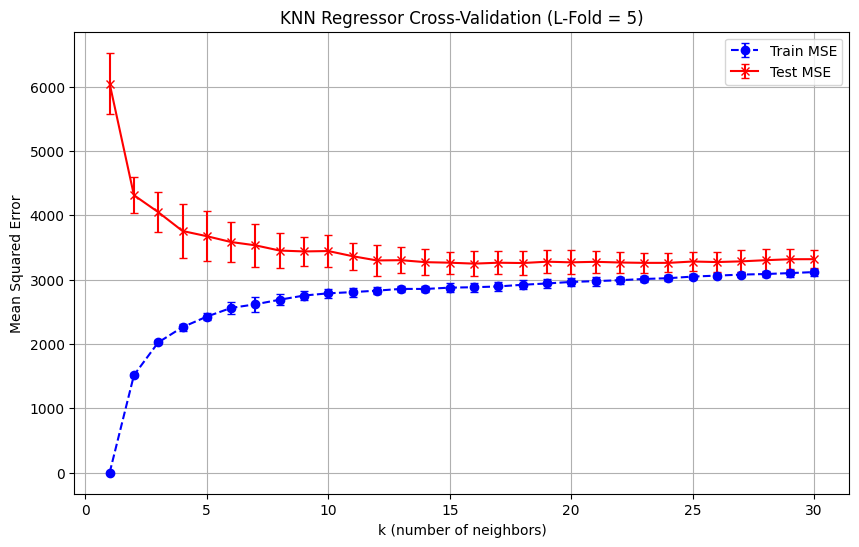

In [ ]:
ks = [r["k"] for r in results]
train_means = [r["train_mean"] for r in results]
test_means = [r["test_mean"] for r in results]
train_cis = [r["train_ci"] for r in results]
test_cis = [r["test_ci"] for r in results]

plt.figure(figsize=(10, 6))
plt.errorbar(ks, train_means, yerr=train_cis, label="Train MSE", capsize=3, color='blue', marker='o', linestyle='--')
plt.errorbar(ks, test_means, yerr=test_cis, label="Test MSE", capsize=3, color='red', marker='x', linestyle='-')
plt.xlabel("k (number of neighbors)")
plt.ylabel("Mean Squared Error")
plt.title("KNN Regressor Cross-Validation (L-Fold = {})".format(lfold.get_n_splits()))
plt.legend()
plt.grid(True)
plt.show()


***explanation***:-

*Overfitting (low k, k=1–10):*

Train MSE is very low and test MSE is high

Model memorizes training data but generalizes poorly

*Underfitting (high k, e.g., k=20–30):*

Both train and test MSE are high

Model is too simple to capture patterns ( averaging too many neighbors)

*Best generalization (sweet spot):*
Somewhere in the middle (k ≈ 10–20)

Train and test MSE are reasonably close

Test MSE is at its minimum → this is the best-performing model (Best k = 16
Test MSE = 3249.88 ± 188.70)





***The effect of the parameter L of the CV procedure.***

***Note: we might want to repeat the above process with different values for L to get an intuition of its effect.***

In [ ]:
L_values = [3, 5, 10]
cv_results_by_L = {}

for L in L_values:
    print(f"Running CV with L={L}")
    lfold = LFold(n_splits=L, shuffle=True, random_state=42)
    cv_results_by_L[L] = evaluate_knn_with_lfold(x, y, lfold)

Running CV with L=3
Running CV with L=5
Running CV with L=10


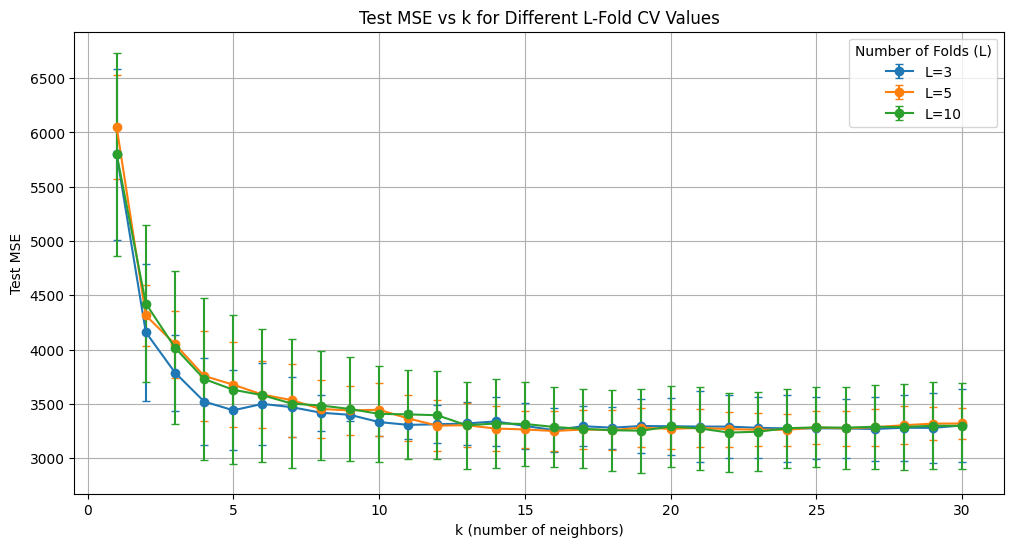

In [ ]:
plt.figure(figsize=(12, 6))

for L in L_values:
    res = cv_results_by_L[L]
    ks = [r["k"] for r in res]
    test_means = [r["test_mean"] for r in res]
    test_cis = [r["test_ci"] for r in res]

    plt.errorbar(ks, test_means, yerr=test_cis, label=f"L={L}", capsize=3, marker='o', linestyle='-')

plt.xlabel("k (number of neighbors)")
plt.ylabel("Test MSE")
plt.title("Test MSE vs k for Different L-Fold CV Values")
plt.legend(title="Number of Folds (L)")
plt.grid(True)
plt.show()



*** [Automatic Model Selection]***

***I Implement a version of the KNN regressor that automatically chooses an appropriate value of K from a list of options by performing a cross-validation on the training set at fitting time. As usually, use the scikit-learn paradigm, i.e., use the following template.***

In [ ]:
class KnnRegressorCV(BaseEstimator):
      def __init__(self, ks=list(range(1, 21)), cv=LFold(5)):
          # YOUR CODE HERE
          self.ks = ks
          self.cv = cv
          self.k_ = None

      def fit(self, x, y):
          # YOUR CODE HERE
          x = np.array(x)
          y = np.array(y)
          avg_test_errors = []
          for k in self.ks:
            test_errors = []
            for train_idx, test_idx in self.cv.split(x):
                x_train, y_train = x[train_idx], y[train_idx]
                x_test, y_test = x[test_idx], y[test_idx]

                model = KnnRegressor(k=k)
                model.fit(x_train, y_train)
                y_pred = model.predict(x_test)

                test_errors.append(mse(y_test, y_pred))
            avg_test_errors.append(np.mean(test_errors))
          # Pick k with lowest average test error
          best_index = np.argmin(avg_test_errors)
          self.k_ = self.ks[best_index]
          self.model_ = KnnRegressor(k=self.k_)
          self.model_.fit(x, y)
          return self


      def predict(self, x):
          return self.model_.predict(x)
      # YOUR CODE HERE

In [ ]:
# Outer train/test split
x_train, x_test, y_train, y_test = train_test_split(
    diabetes.data, diabetes.target, train_size=0.7, random_state=1
)

model_cv = KnnRegressorCV(ks=list(range(1, 21)), cv=LFold(n_splits=5, shuffle=True, random_state=42))
model_cv.fit(x_train, y_train)

print("Chosen k by internal CV:", model_cv.k_)

y_train_pred = model_cv.predict(x_train)
y_test_pred = model_cv.predict(x_test)

print("Train MSE:", mse(y_train, y_train_pred))
print("Test MSE:", mse(y_test, y_test_pred))


Chosen k by internal CV: 20
Train MSE: 2986.898268608414
Test MSE: 3310.6863345864663


In [ ]:
outer_lfold = LFold(n_splits=5, shuffle=True, random_state=0)
k_values = list(range(1, 21))

all_test_errors = []
all_chosen_ks = []

for outer_fold, (train_idx, test_idx) in enumerate(outer_lfold.split(x)):
    x_train, y_train = x[train_idx], y[train_idx]
    x_test, y_test = x[test_idx], y[test_idx]

    model = KnnRegressorCV(ks=k_values, cv=LFold(n_splits=5, shuffle=True, random_state=outer_fold))
    model.fit(x_train, y_train)

    y_test_pred = model.predict(x_test)
    test_error = mse(y_test, y_test_pred)

    all_test_errors.append(test_error)
    all_chosen_ks.append(model.k_)

    print(f"Outer Fold {outer_fold+1}: Chosen k = {model.k_}, Test MSE = {test_error:.2f}")


Outer Fold 1: Chosen k = 17, Test MSE = 3356.58
Outer Fold 2: Chosen k = 18, Test MSE = 3087.01
Outer Fold 3: Chosen k = 17, Test MSE = 3437.86
Outer Fold 4: Chosen k = 15, Test MSE = 2808.42
Outer Fold 5: Chosen k = 14, Test MSE = 3205.10


In [ ]:
print("\n--- Summary ---")
print("Mean Test MSE:", np.mean(all_test_errors))
print("Std Test MSE:", np.std(all_test_errors))
print("Mean chosen k:", np.mean(all_chosen_ks))
print("Chosen k values across folds:", all_chosen_ks)



--- Summary ---
Mean Test MSE: 3178.9934031083817
Std Test MSE: 221.36697449580427
Mean chosen k: 16.2
Chosen k values across folds: [17, 18, 17, 15, 14]


The ability of internal cross-validation to select the best model (i.e., best `k` in KNN) depends on several factors:

1. **Representativeness of training folds**: If folds don't reflect the diversity of the full dataset, performance estimates can be misleading.
2. **Stability of model performance**: High variance in fold errors can cause inconsistent or unreliable model selection.
3. **Dataset size**: Small datasets lead to high variance and unstable model choices.
4. **Number of CV folds (`L`)**: Higher `L` generally improves estimate stability and reliability of selected hyperparameters.
5. **Range of tested `k` values**: Too wide or sparse a range can cause under- or over-smoothing, skipping better options.
6. **Noise and data complexity**: CV may favor different `k` values depending on the level of noise and structure in the data.

When used correctly with appropriate fold count and data size, internal CV is a powerful and practical method for model selection.